# 1 Load and Inspect Raw Data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

In [2]:
def load_data(path): 
    data = pd.read_csv(path)
    ecg_signals = data.drop(columns = ["name", "label"]).to_numpy()
    
    labels = []
    for i in data["label"]:
        if i == 1:
            labels.append(1)
        else:
            labels.append(0)
    labels = np.array(labels)
    
    return ecg_signals, labels

X_train, y_train = load_data("data/train.csv")
X_val, y_val = load_data("data/val.csv")
print("Train:", X_train.shape, "Validation:", X_val.shape)
print("Train AF/non-AF:", np.bincount(y_train))

Train: (2000, 2000) Validation: (1000, 2000)
Train AF/non-AF: [1822  178]


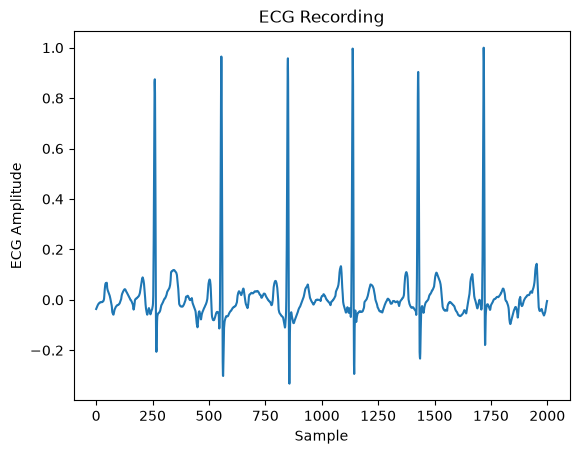

0


In [3]:
plt.plot(X_train[1])
plt.xlabel("Sample")
plt.ylabel("ECG Amplitude")
plt.title("ECG Recording")

plt.show()
print(y_train[1])


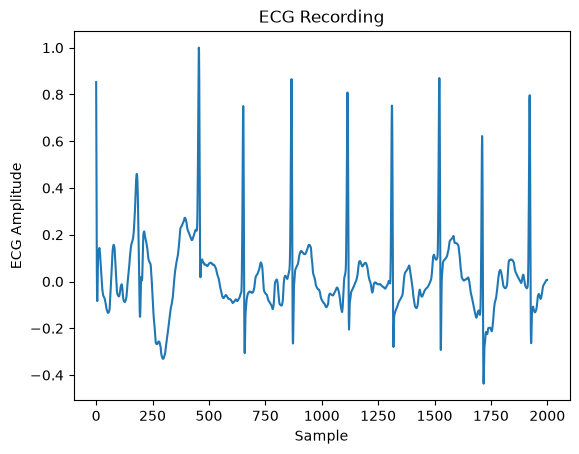

1


In [4]:
#AF
plt.plot(X_train[2])
plt.xlabel("Sample")
plt.ylabel("ECG Amplitude")
plt.title("ECG Recording")

plt.show()
print(y_train[2])


# 2 Train and Evaluate Classifiers



In [5]:
# Write Cross-Validation, Hyperparameter Tuning, and Model Saving Scaffold. 

from sklearn.model_selection import StratifiedKFold, ParameterGrid
from sklearn.metrics import roc_auc_score
import joblib

def cross_validate(X, y, params, train_predict, folds=3):
    stratK = StratifiedKFold(n_splits = folds, shuffle = True, random_state = 42)
    best_params = None
    best_auc = 0

    for settings in ParameterGrid(params):
        scores = []
        
        for train_idx, test_idx in stratK.split(X, y):
            X_train = X[train_idx]
            y_train = y[train_idx]
            X_test = X[test_idx]
            y_test = y[test_idx]

            prob = train_predict(X_train, y_train, X_test, settings)
            auc = roc_auc_score(y_test, prob)
            scores.append(auc)
            
        avg_auc = np.mean(scores)
        
        if avg_auc > best_auc:
            best_auc = avg_auc
            best_params = settings
        

    return best_params

def save_model(model, path):
    joblib.dump(model, path)

In [6]:
# RandomForestClassifier
from sklearn.ensemble import RandomForestClassifier
from scipy.signal import butter, sosfiltfilt, find_peaks

sos = butter(4, [0.5, 40], btype="bandpass", fs=300, output="sos") # Bandpass filter: 0.5–40 Hz


def extract_features(signal, distance=90, prominence=0.45):
    # Filter ECG
    signal = sosfiltfilt(sos, signal)

    # Detect R peaks
    peaks, peaks_properties = find_peaks(
        signal, distance=distance, prominence=prominence
    )

    rr_intervals = np.diff(peaks)
    
    if len(rr_intervals) > 0:
        mean_rr = np.mean(rr_intervals)
        std_rr = np.std(rr_intervals)
    else:
        mean_rr = 0
        std_rr = 0

    if len(rr_intervals) > 1:
        rmssd = np.sqrt(np.mean(np.diff(rr_intervals)**2))
    else:
        rmssd = 0

    peak_count = len(peaks)
    signal_std = np.std(signal)

    return [mean_rr, std_rr, rmssd, peak_count, signal_std]
    
# Random Forest
def train_predict(X_train, y_train, X_test, settings):
    model = RandomForestClassifier(**settings, class_weight="balanced", random_state=42)
    model.fit(X_train, y_train)

    return model.predict_proba(X_test)[:, 1]

# ECG features
X_features = np.array([extract_features(signal) for signal in X_train])

# Params
rf_params = {"n_estimators": [100, 200], "max_depth": [5, 10, None]}

# Cross-validation
rf_best_params = cross_validate(X_features, y_train, rf_params, train_predict, folds=3)

# Final
rf_model = RandomForestClassifier(**rf_best_params, class_weight="balanced", random_state=42)

rf_model.fit(X_features, y_train)
save_model(rf_model, "src/my_model.pkl")

In [7]:
X_val_features = np.array([
    extract_features(signal) for signal in X_val
])

rf_probabilities = rf_model.predict_proba(X_val_features)[:, 1]

rf_auc = roc_auc_score(y_val, rf_probabilities)
print("Random Forest Validation AUC:", rf_auc)

Random Forest Validation AUC: 0.8503373253246833


In [8]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
device = torch.device("mps")


# CNN based decoder

class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv1d(1, 16, kernel_size=16), # CNN Layer 1
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.Conv1d(16, 32, kernel_size=5, padding=2), # CNN Layer 2
            nn.ReLU(),
            nn.MaxPool1d(2),

            nn.AdaptiveAvgPool1d(1), # Output
            nn.Flatten(),
            nn.Linear(32, 1)
            )
    def forward(self, x):
        return self.network(x).squeeze(1)
            

    
def train_predict_cnn(X_train, y_train, X_test, settings):
    model = CNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["lr"])

    # Loss function
    pos_weight = torch.tensor(
        np.sum(y_train == 0) / np.sum(y_train == 1),
        dtype=torch.float32
    )
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

    # Convert data to tensors
    X = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
    y = torch.tensor(y_train, dtype=torch.float32)

    # Training batches
    loader = DataLoader(
        TensorDataset(X, y),
        batch_size=32,
        shuffle=True
    )

    # Train CNN
    model.train()

    for epoch in range(settings["epochs"]):
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            predictions = model(x_batch)
            loss = loss_fn(predictions, y_batch)
            loss.backward()
            optimizer.step()

    # Evaluate CNN
    model.eval()

    with torch.no_grad():
        X_test_tensor = torch.tensor(X_test, dtype=torch.float32).unsqueeze(1).to(device)
        probabilities = torch.sigmoid(model(X_test_tensor))

    # AF probabilities
    return probabilities.cpu().numpy()



def train_final_cnn(X, y, settings):
    
    model = CNN().to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=settings["lr"])

    # Loss function
    pos_weight = torch.tensor(
        np.sum(y == 0) / np.sum(y == 1),
        dtype=torch.float32
    )
    loss_fn = nn.BCEWithLogitsLoss(pos_weight=pos_weight.to(device))

    # Convert data to tensors
    X_tensor = torch.tensor(X, dtype=torch.float32).unsqueeze(1)
    y_tensor = torch.tensor(y, dtype=torch.float32)

    # Training batches
    loader = DataLoader(
        TensorDataset(X_tensor, y_tensor),
        batch_size=32,
        shuffle=True
    )

    # Train CNN
    model.train()

    for epoch in range(settings["epochs"]):
        for x_batch, y_batch in loader:
            x_batch = x_batch.to(device)
            y_batch = y_batch.to(device)
            optimizer.zero_grad()
            predictions = model(x_batch)
            loss = loss_fn(predictions, y_batch)
            loss.backward()
            optimizer.step()

    model.eval()
    return model


# Hyperparameters
params = {
    "lr": [0.001, 0.0003],
    "epochs": [5, 10]
}



best_params = cross_validate(
    X_train, y_train, params, train_predict_cnn, folds=3
)

print(best_params)

# Final CNN
model = train_final_cnn(X_train, y_train, best_params)
torch.save(model.state_dict(), "src/torch_model.pt")

{'epochs': 10, 'lr': 0.001}


In [9]:
# Evaluate CNN
cnn_model = CNN().to(device)
cnn_model.load_state_dict(torch.load("src/torch_model.pt", map_location=device))
cnn_model.eval()

X_val_tensor = torch.tensor(X_val, dtype=torch.float32).unsqueeze(1).to(device)
with torch.no_grad():
    cnn_probabilities = torch.sigmoid(cnn_model(X_val_tensor)).cpu().numpy()

cnn_auc = roc_auc_score(y_val, cnn_probabilities)
print("CNN Validation AUC:", cnn_auc)

CNN Validation AUC: 0.6224423093526068
